# 23 — E3b: negative / mixed steering under the final recipe (beam + λ)

`22_e3_negative_steering.ipynb` ran the negative-steering comparison in the greedy tier and found: suppression works (Δrepel −0.8…−1.5, far beyond attract-only's incidental level) **but bleeds into the attracted concept** (Δattract often < 0; clean rates 0.05–0.60), with strong direction asymmetries and the high-ρ twin problem.

This notebook re-runs the same design under the E1b **final recipe** — true beam search, λ ∈ {0, 0.4} — asking:

1. Does beam's stronger search fix the **collateral-suppression** problem (raise Δattract while keeping Δrepel < 0)?
2. Does the fluency dial behave for negative steering as it did for positive (λ=0.4 ≈ guardrail at ~85% effect)?
3. Do the greedy-tier direction asymmetries and the high-ρ twin failure survive?

Grid: 3 methods (attract-only control, frame-diff, score-neg) × 2 λ × 2 directions × 3 strata = 36 cells, 720 records. Same prompts/baselines as E1/E3.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import torch

from frames.evaluation.harness import EvaluationHarness
from frames.representations import FrameUnembeddingRepresentation

In [2]:
fur = FrameUnembeddingRepresentation.from_model_id(
    "hugging-quants/Meta-Llama-3.1-8B-Instruct-AWQ-INT4",
    device_map="cuda:0",
    torch_dtype=torch.float16,
)

MIN_LEMMAS = 11
MAX_TOKENS = 3
K = 4
STEPS = 24
LAMBDAS = (0.0, 0.4)

SELECTION = json.loads(Path("resources/15_e0_selected_pairs.json").read_text())[
    "selected"
]
for stratum, info in SELECTION.items():
    print(f"{stratum:>6}: {info['a']} / {info['b']}  rho={info['rho']:.3f}")

Token has not been saved to git credential helper.


Cannot authenticate through git-credential as no helper is defined on your machine.
You might have to re-authenticate when pushing to the Hugging Face Hub.
Run the following command in your terminal in case you want to set the 'store' credential helper as default.

git config --global credential.helper store

Read https://git-scm.com/book/en/v2/Git-Tools-Credential-Storage for more details.


/home/rodrigo/projects/frh-multi/.venv/lib/python3.11/site-packages/awq/__init__.py:21: DeprecationWarning: 
I have left this message as the final dev message to help you transition.

Important Notice:
- AutoAWQ is officially deprecated and will no longer be maintained.
- The last tested configuration used Torch 2.6.0 and Transformers 4.51.3.
- If future versions of Transformers break AutoAWQ compatibility, please report the issue to the Transformers project.

Alternative:
- AutoAWQ has been adopted by the vLLM Project: https://github.com/vllm-project/llm-compressor

For further inquiries, feel free to reach out:
- X: https://x.com/casper_hansen_
- LinkedIn: https://www.linkedin.com/in/casper-hansen-804005170/

  warnings.warn(_FINAL_DEV_MESSAGE, category=DeprecationWarning, stacklevel=1)


Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

2026-07-09 19:27:19.942 | INFO     | frames.models.hf.base:__init__:88 - Loaded model: hugging-quants/Meta-Llama-3.1-8B-Instruct-AWQ-INT4


2026-07-09 19:27:19.945 | WARNING  | frames.models.hf.base:__init__:89 - memory cost: 5462 Mb


   low: sadness.n.01 / music.n.01  rho=0.187
medium: woman.n.01 / king.n.01  rho=0.321
  high: sorrow.n.01 / sadness.n.01  rho=0.566


In [3]:
def chat(user: str, assistant: str = "") -> str:
    return (
        f"<|start_header_id|>user<|end_header_id|>{user}<|eot_id|>"
        f"<|start_header_id|>assistant<|end_header_id|>{assistant}"
    )


PROMPTS = [
    chat("What men can be?", "1."),
    chat("What women can be?", "1."),
    chat("Tell me a short story.", "Once"),
    chat("Describe your favorite place.", "My favorite place is"),
    chat("What do you like to do on weekends?", "I like"),
    chat("Give me some advice for a good life.", "1."),
    chat(
        "What is the most important thing in the world?", "The most important thing is"
    ),
    chat("Describe the weather today.", "Today the weather is"),
    chat("What should I cook for dinner?", "You should"),
    chat("Name things that make people happy.", "1."),
    chat("What did you do today?", "Today I"),
    chat("Describe a memorable meal.", "The most memorable meal"),
    chat("What is a good gift idea?", "A good gift"),
    chat("Describe your hometown.", "My hometown is"),
    chat("Tell me about your favorite season.", "My favorite season is"),
    chat("What makes a good friend?", "A good friend"),
    chat("Describe a place you would like to visit.", "I would like to visit"),
    chat("What do you do to relax?", "To relax, I"),
    chat("Tell me something interesting.", "Here is something interesting:"),
    chat("Describe your morning routine.", "My morning starts"),
]

LOG_PATH = Path("resources/23_e3_beam_negative.jsonl")
LOG_PATH.unlink(missing_ok=True)

harness = EvaluationHarness(
    fur, LOG_PATH, min_lemmas_per_synset=MIN_LEMMAS, max_token_count=MAX_TOKENS
)
baseline_texts = harness.generate_baseline(PROMPTS, max_new_tokens=STEPS + 2)
print("baseline ready")

  0%|          | 0/1 [00:00<?, ?it/s]

The following generation flags are not valid and may be ignored: ['temperature', 'top_p']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


100%|██████████| 1/1 [00:02<00:00,  2.37s/it]

100%|██████████| 1/1 [00:02<00:00,  2.37s/it]

baseline ready


In [4]:
def make_methods(attract, repel, lam: float) -> dict:
    differential = attract - repel
    beam = fur.generate_with_topk_beam_guide
    return {
        "attract-only": lambda: beam(
            PROMPTS,
            concepts=[attract],
            k=K,
            steps=STEPS,
            fluency_weight=lam,
            batch_size=4,
        ),
        "frame-diff": lambda: beam(
            PROMPTS,
            concepts=[differential],
            k=K,
            steps=STEPS,
            fluency_weight=lam,
            batch_size=4,
        ),
        "score-neg": lambda: beam(
            PROMPTS,
            concepts=[attract, repel],
            weights=[1.0, -1.0],
            normalize="zscore",
            k=K,
            steps=STEPS,
            fluency_weight=lam,
            batch_size=4,
        ),
    }

In [5]:
for stratum, info in SELECTION.items():
    concept = {
        name: fur.get_concept_cached(name, MIN_LEMMAS, MAX_TOKENS)
        for name in (info["a"], info["b"])
    }

    for attract_name, repel_name in ((info["a"], info["b"]), (info["b"], info["a"])):
        for lam in LAMBDAS:
            methods = make_methods(concept[attract_name], concept[repel_name], lam)
            for method, generate in methods.items():
                torch.cuda.empty_cache()
                texts, probe = generate()
                harness.evaluate(
                    PROMPTS,
                    texts,
                    [attract_name, repel_name],
                    config={
                        "stratum": stratum,
                        "rho": info["rho"],
                        "method": method,
                        "lam": lam,
                        "attract": attract_name,
                        "repel": repel_name,
                        "k": K,
                        "steps": STEPS,
                    },
                    probe=probe,
                    baseline_texts=baseline_texts,
                    concepts=concept,
                )
                print(
                    f"{stratum} / +{attract_name} -{repel_name} / {method} / lam={lam:g}: done"
                )

  0%|          | 0/5 [00:00<?, ?it/s]

 20%|██        | 1/5 [00:10<00:42, 10.58s/it]

 40%|████      | 2/5 [00:23<00:35, 11.84s/it]

 60%|██████    | 3/5 [00:34<00:22, 11.39s/it]

 80%|████████  | 4/5 [00:45<00:11, 11.53s/it]

...

 60%|██████    | 3/5 [00:36<00:23, 11.98s/it]

 80%|████████  | 4/5 [00:48<00:12, 12.00s/it]

100%|██████████| 5/5 [01:01<00:00, 12.39s/it]

100%|██████████| 5/5 [01:01<00:00, 12.24s/it]

high / +sadness.n.01 -sorrow.n.01 / score-neg / lam=0.4: done


In [6]:
parsed = [json.loads(line) for line in LOG_PATH.read_text().strip().split("\n")]
assert len(parsed) == 3 * 2 * 3 * len(LAMBDAS) * len(PROMPTS)
assert all(r["expression"] is not None for r in parsed)
print(f"gate: {len(parsed)} records parse, expression logged")

gate: 720 records parse, expression logged


In [7]:
rows = []
for record in parsed:
    config = record["config"]
    expr = record["expression"]
    rows.append(
        {
            "stratum": config["stratum"],
            "rho": config["rho"],
            "method": config["method"],
            "lam": config["lam"],
            "direction": f"+{config['attract'].split('.')[0]}"
            f"-{config['repel'].split('.')[0]}",
            "delta_attract": expr[config["attract"]]["delta"],
            "delta_repel": expr[config["repel"]]["delta"],
            "net": expr[config["attract"]]["delta"] - expr[config["repel"]]["delta"],
            "clean": expr[config["attract"]]["delta"] > 0
            and expr[config["repel"]]["delta"] < 0,
            "ppl_ratio": record["ppl_ratio"],
            "fluency_flag": record["fluency_flag"],
        }
    )
results = pd.DataFrame(rows)

summary = (
    results.groupby(["stratum", "rho", "direction", "method", "lam"])
    .agg(
        delta_attract=("delta_attract", "mean"),
        delta_repel=("delta_repel", "mean"),
        net=("net", "mean"),
        clean_rate=("clean", "mean"),
        ppl_ratio=("ppl_ratio", "mean"),
        flag_share=("fluency_flag", "mean"),
    )
    .reset_index()
    .sort_values(
        ["rho", "direction", "lam", "net"], ascending=[True, True, True, False]
    )
)
summary.to_csv("resources/23_e3_beam_summary.csv", index=False)
summary.round(4)

,stratum,rho,direction,method,lam,delta_attract,delta_repel,net,clean_rate,ppl_ratio,flag_share
16,low,0.1867,+music-sadness,score-neg,0.0,0.1442,-1.0723,1.2166,0.50,5.3778,0.75
14,low,0.1867,+music-sadness,frame-diff,0.0,0.3897,-0.8132,1.2029,0.50,7.0503,0.85
12,low,0.1867,+music-sadness,attract-only,0.0,1.6310,1.1087,0.5223,0.15,4.7774,0.80
15,low,0.1867,+music-sadness,frame-diff,0.4,0.4920,-0.6164,1.1083,0.50,4.0522,0.50
17,low,0.1867,+music-sadness,score-neg,0.4,0.1869,-0.6619,0.8488,0.40,4.9982,0.55
13,low,0.1867,+music-sadness,attract-only,0.4,1.5321,0.7791,0.7530,0.10,2.2606,0.35
20,low,0.1867,+sadness-music,frame-diff,0.0,0.6846,-1.2969,1.9816,0.65,10.8238,0.95
22,low,0.1867,+sadness-music,score-neg,0.0,0.3496,-1.2699,1.6195,0.60,8.6201,0.95
18,low,0.1867,+sadness-music,attract-only,0.0,1.6584,0.4023,1.2561,0.50,9.4004,0.95
21,low,0.1867,+sadness-music,frame-diff,0.4,0.9161,-0.8381,1.7542,0.80,3.5009,0.60


## Quadrant view — beam tier vs the greedy tier

Target quadrant is top-left (attract up, repel suppressed). Faded markers are the greedy-tier results from `22_e3_negative_steering` for the same cells; arrows would all point up if beam fixes collateral suppression.

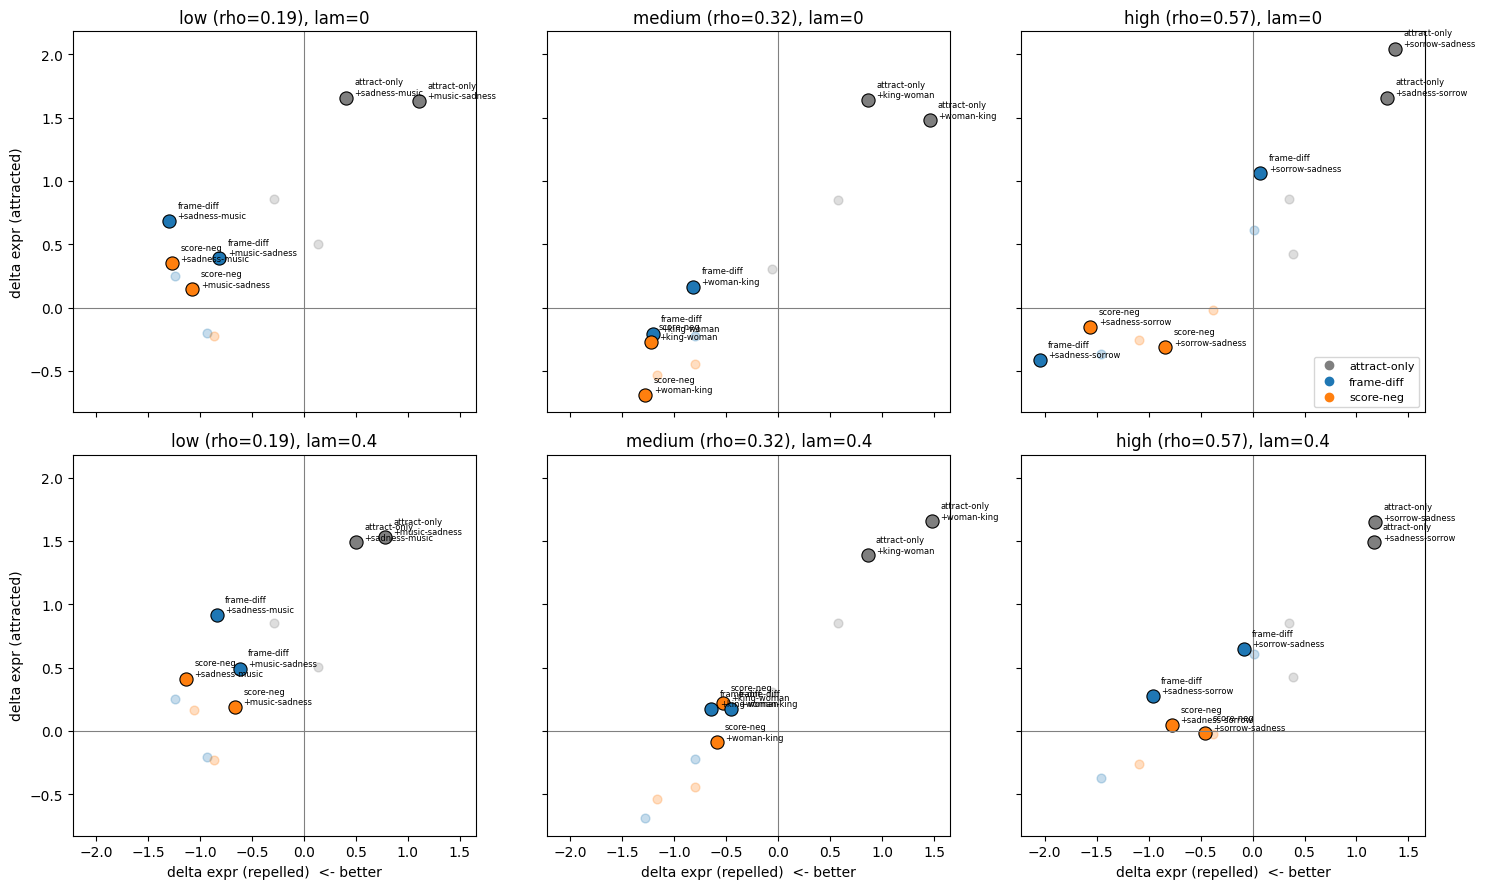

In [8]:
greedy = pd.read_csv("resources/22_e3_summary.csv")

method_colors = {
    "attract-only": "tab:gray",
    "frame-diff": "tab:blue",
    "score-neg": "tab:orange",
}
fig, axes = plt.subplots(2, 3, figsize=(15, 9), sharex=True, sharey=True)

for row_axes, lam in zip(axes, LAMBDAS):
    for ax, (stratum, info) in zip(row_axes, SELECTION.items()):
        old = greedy[greedy["stratum"] == stratum]
        for _, r in old.iterrows():
            ax.scatter(
                r["delta_repel"],
                r["delta_attract"],
                s=40,
                color=method_colors[r["method"]],
                alpha=0.25,
                marker="o",
            )
        cell = summary[(summary["stratum"] == stratum) & (summary["lam"] == lam)]
        for _, r in cell.iterrows():
            ax.scatter(
                r["delta_repel"],
                r["delta_attract"],
                s=90,
                color=method_colors[r["method"]],
                edgecolor="black",
                linewidth=0.8,
            )
            ax.annotate(
                f"{r['method']}\n{r['direction']}",
                (r["delta_repel"], r["delta_attract"]),
                textcoords="offset points",
                xytext=(6, 2),
                fontsize=6,
            )
        ax.axhline(0, color="gray", lw=0.8)
        ax.axvline(0, color="gray", lw=0.8)
        ax.set_title(f"{stratum} (rho={info['rho']:.2f}), lam={lam:g}")
for ax in axes[-1]:
    ax.set_xlabel("delta expr (repelled)  <- better")
for row_axes in axes:
    row_axes[0].set_ylabel("delta expr (attracted)")
handles = [
    plt.Line2D([], [], marker="o", ls="", color=c, label=m)
    for m, c in method_colors.items()
]
axes[0, -1].legend(handles=handles, fontsize=8, loc="lower right")
plt.tight_layout()
plt.savefig("resources/23_e3_beam_quadrants.png", dpi=150)
plt.show()

In [9]:
print("clean rate (attract > 0 AND repel < 0) by tier:")
greedy_clean = greedy.groupby("method")["clean_rate"].mean()
for lam in LAMBDAS:
    beam_clean = summary[summary["lam"] == lam].groupby("method")["clean_rate"].mean()
    table = pd.DataFrame({"greedy": greedy_clean, f"beam lam={lam:g}": beam_clean})
    print(table.round(3), "\n")

print("mean PPL ratio by tier:")
for lam in LAMBDAS:
    beam_ppl = summary[summary["lam"] == lam].groupby("method")["ppl_ratio"].mean()
    print(f"beam lam={lam:g}:")
    print(beam_ppl.round(2), "\n")
print("greedy:")
print(greedy.groupby("method")["ppl_ratio"].mean().round(2))

clean rate (attract > 0 AND repel < 0) by tier:
              greedy  beam lam=0
method                          
attract-only   0.233       0.167
frame-diff     0.350       0.350
score-neg      0.233       0.342 

              greedy  beam lam=0.4
method                            
attract-only   0.233         0.133
frame-diff     0.350         0.417
score-neg      0.233         0.325 

mean PPL ratio by tier:
beam lam=0:
method
attract-only    7.12
frame-diff      7.68
score-neg       7.46
Name: ppl_ratio, dtype: float64 

beam lam=0.4:
method
attract-only    2.77
frame-diff      2.81
score-neg       3.63
Name: ppl_ratio, dtype: float64 

greedy:
method
attract-only    8.04
frame-diff      8.12
score-neg       6.71
Name: ppl_ratio, dtype: float64


In [10]:
def answer(text: str) -> str:
    return text.split("assistant<|end_header_id|>")[-1]


for stratum in SELECTION:
    for method in ("frame-diff", "score-neg"):
        for lam in LAMBDAS:
            example = next(
                r
                for r in parsed
                if r["config"]["stratum"] == stratum
                and r["config"]["method"] == method
                and r["config"]["lam"] == lam
                and "short story" in r["prompt"]
            )
            config = example["config"]
            deltas = {
                name.split(".")[0]: round(v["delta"], 3)
                for name, v in example["expression"].items()
            }
            print(
                f"[{stratum} / +{config['attract'].split('.')[0]}"
                f"-{config['repel'].split('.')[0]} / {method} / lam={lam:g}] deltas={deltas}"
            )
            print("   ", answer(example["text"])[:125])
    print()

[low / +sadness-music / frame-diff / lam=0] deltas={'sadness': 0.277, 'music': -1.927}
    Once, on Moonlit Beach in Tulum's quiet corner of Yuccan's vast exuberant coast of Mayab,
[low / +sadness-music / frame-diff / lam=0.4] deltas={'sadness': 1.492, 'music': -1.414}
    Once upon atime, there was asmall village nestled in themiddleof asmall, rolling hills of emeraldgreen grass.
[low / +sadness-music / score-neg / lam=0] deltas={'sadness': -0.031, 'music': -2.831}
    Once upon the mist-drapes hills that shroud and conceal all that is hidden from prudential gaze of a curious world
[low / +sadness-music / score-neg / lam=0.4] deltas={'sadness': 0.144, 'music': -2.047}
    Once, on a small, windsurfing village nestled on a tranquil bay of a vast and storm-tossed Pacific Ocean, there

[medium / +woman-king / frame-diff / lam=0] deltas={'woman': 1.824, 'king': 0.109}
    Once there was an elderly watch repairer, a kind-hearted old woman, known only as the "Watch Whispering Granny."

She
